# BSE Summer School Project

Task: design a long-term portfolio strategy for a private wealth management client based in the US with assets worth USD 100 million.

The portfolio must meet the following conditions:

• Invested in different asset classes (Bonds, Commodities, Equities, Money
Market, Precious Metals, Real Estate), with a **minimum investment of 20% in bonds or money market instruments** (no constraint on other asset classes)

• **No short sales **

• asset classes ETFs with a **minimum history of 10 years**

• Keep the number of ETFs low.

• You must **show the frontier** to your client so they understand the risk-return trade-off

• Find also the portfolio with the maximum expected return subject to a 1-month maximum value at risk constraint of 3% with a 99% confidence **texte en gras** on the portfolio return (you may assume normality or use the historical VaR)

• You must at least discuss **estimation risk**. Implementing Black-Litterman or any other
correction method is optional.

Prepare a report of not more than 5 pages with your proposal. Justify your choices. In particular, justify the choice of ETFs and asset classes in terms of their role in diversification and expected performance.

Do not submit your code.

Have fun!

# ETFs Selection

1. Equities - US large-cap equities:
SPY – SPDR S&P 500 ETF

2. Bonds - US investment-grade bonds (government + corporate):
AGG – iShares Core U.S. Aggregate Bond ETF

3. Money Market - short-term Treasury bonds:
SHV – iShares Short Treasury Bond ETF

5. Precious Metals - Gold:
GLD – SPDR Gold Shares

6. Real Estate - US REIT exposure:
VNQ – Vanguard Real Estate ETF


In [2]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
#import cvxpy as cp

from scipy.stats import t
from scipy.stats import norm
from scipy.stats import skew, kurtosis

# Individual performances

[*********************100%***********************]  5 of 5 completed


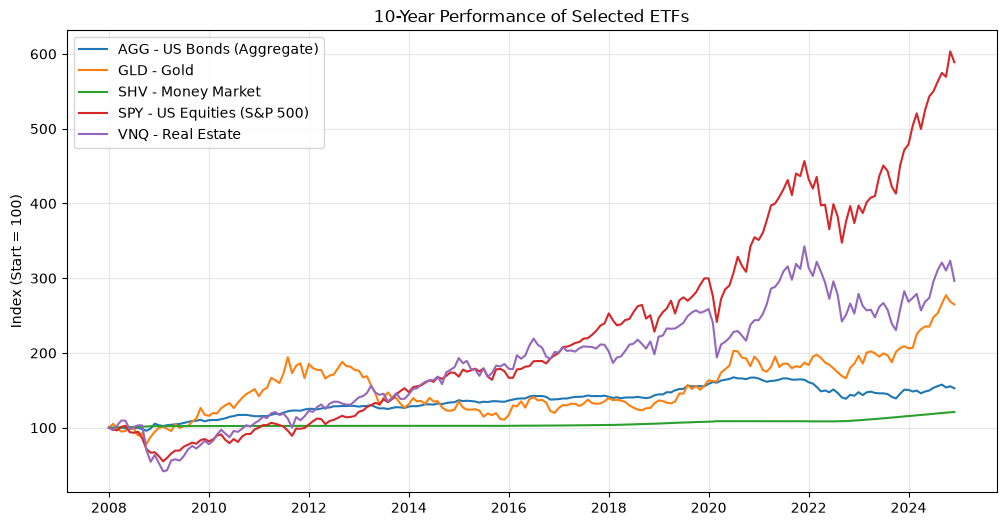

In [3]:
# ETFs selected
etfs = ['SPY', 'AGG', 'SHV', 'GLD', 'VNQ']
names = {
    'SPY': 'SPY - US Equities (S&P 500)',
    'AGG': 'AGG - US Bonds (Aggregate)',
    'SHV': 'SHV - Money Market',
    'GLD': 'GLD - Gold',
    'VNQ': 'VNQ - Real Estate'
}

# Download 10 years of monthly adjusted prices
data = yf.download(etfs, start='2008-01-01', end='2025-01-01', interval='1mo')

# Use 'Close' since prices are already adjusted
data = data['Close'].dropna()

# Normalize prices (start = 100)
normalized = data / data.iloc[0] * 100

# Plot
plt.figure(figsize=(12, 6))
for ticker in normalized.columns:
    plt.plot(normalized.index, normalized[ticker], label=names[ticker])
plt.title('10-Year Performance of Selected ETFs')
plt.ylabel('Index (Start = 100)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Expected Returns

In [4]:
# Calculate monthly returns
returns = data.pct_change().dropna()

# Annualized mean return and volatility
mean_monthly = returns.mean()
vol_monthly = returns.std()

mean_annual = (1 + mean_monthly)**12 - 1
vol_annual = vol_monthly * np.sqrt(12)

# Calculate and store the annualized covariance matrix
cov_matrix = returns.cov() * 12


# Combine into a DataFrame
stats = pd.DataFrame({
    'Monthly return': mean_monthly,
    'Annual Return': mean_annual,
    'Annual Volatility': vol_annual
}).sort_values('Annual Return', ascending=False)

print(stats)

        Monthly return  Annual Return  Annual Volatility
Ticker                                                  
SPY           0.009829       0.124544           0.158704
VNQ           0.007640       0.095629           0.229968
GLD           0.005976       0.074120           0.167876
AGG           0.002186       0.026546           0.047537
SHV           0.000945       0.011402           0.005116


## Correlation matrix

SPY    | SPY - US Equities (S&P 500)
AGG    | AGG - US Bonds (Aggregate)
SHV    | SHV - Money Market
GLD    | GLD - Gold
VNQ    | VNQ - Real Estate


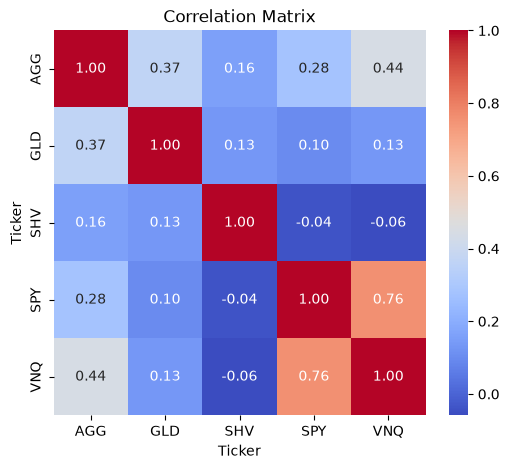

Ticker       AGG       GLD       SHV       SPY       VNQ
Ticker                                                  
AGG     1.000000  0.365247  0.158999  0.276914  0.441669
GLD     0.365247  1.000000  0.131736  0.099938  0.132563
SHV     0.158999  0.131736  1.000000 -0.041888 -0.059170
SPY     0.276914  0.099938 -0.041888  1.000000  0.758741
VNQ     0.441669  0.132563 -0.059170  0.758741  1.000000


In [5]:
# Correlation matrix
corr = returns.corr()


#print une légende
for ticker, desc in names.items():
    print(f"{ticker:<6} | {desc}")


# Plot correlation heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

print(corr)


## risk-return trade-off

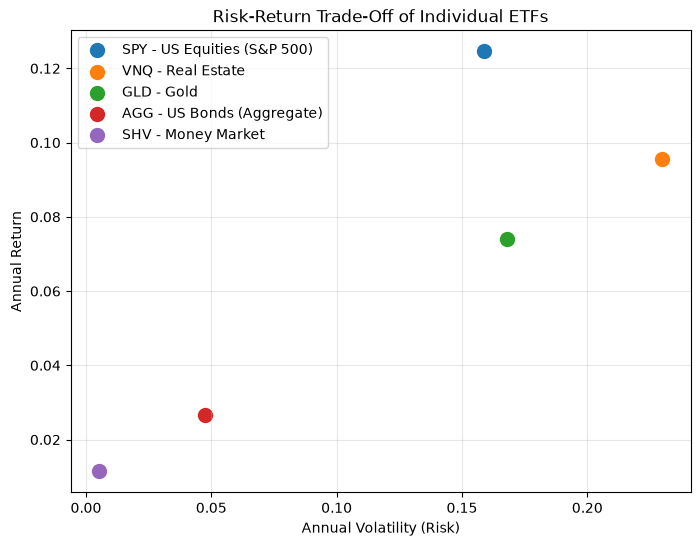

In [6]:
# Scatter plot for risk-return trade-off
plt.figure(figsize=(8, 6))

for ticker in stats.index:
    plt.scatter(stats.loc[ticker, 'Annual Volatility'],
                stats.loc[ticker, 'Annual Return'],
                label=names[ticker], s=100)

# Labels and styling
plt.xlabel('Annual Volatility (Risk)')
plt.ylabel('Annual Return')
plt.title('Risk-Return Trade-Off of Individual ETFs')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## Individual Sharp ratios

We use SHV annual return as the risk free rate.

In [7]:
# Risk-free rate = SHV's annual return
rf = stats.loc['SHV', 'Annual Return']

# Calculate Sharpe ratio for each ETF
stats['Sharpe Ratio'] = (stats['Annual Return'] - rf) / stats['Annual Volatility']

print(stats['Sharpe Ratio'])
print(f"Risk free rate = {rf:.3%}")




Ticker
SPY    0.712912
VNQ    0.366254
GLD    0.373599
AGG    0.318571
SHV    0.000000
Name: Sharpe Ratio, dtype: float64
Risk free rate = 1.140%


# Unconstrained fontier

## Optimal w1 and w2 (without constrains)


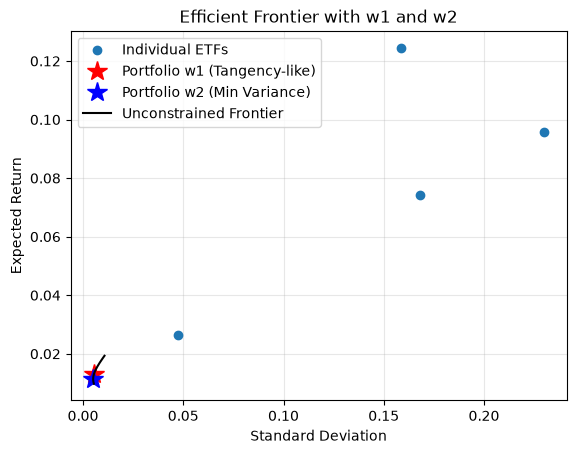

   ETF  w1 (Tangency)  w2 (Min Var)
0  AGG      -0.000056     -0.008286
1  GLD       0.001003     -0.002798
2  SHV       0.986441      1.007978
3  SPY       0.015418      0.000564
4  VNQ      -0.002807      0.002542


In [8]:
# Inputs: mean_annual and cov_matrix defined from previous cells
ER = mean_annual.values  # Expected annual returns as array
V = cov_matrix.values     # Covariance matrix as array
n = len(ER)


w1 = np.linalg.inv(V) @ ER / np.sum(np.linalg.inv(V) @ ER)
w2 = np.linalg.inv(V) @ np.ones(n) / np.sum(np.linalg.inv(V) @ np.ones(n))

# Expected return and volatility for w1 and w2
ER1 = w1 @ ER
ER2 = w2 @ ER

s1 = np.sqrt(w1 @ V @ w1)
s2 = np.sqrt(w2 @ V @ w2)

s12 = w1 @ V @ w2


# Build frontier between w1 and w2
p = np.arange(-1, 5, 0.01)
ERp = np.zeros(len(p))
sp = np.zeros(len(p))

for j in range(len(p)):
    ERp[j] = p[j]*ER1 + (1 - p[j])*ER2
    sp[j] = np.sqrt(p[j]**2 * s1**2 + (1 - p[j])**2 * s2**2 + 2*p[j]*(1 - p[j])*s12)

# Plot
plt.figure()

# ETFs as points - Use the covariance matrix for volatility
# Ensure the index for plotting is correct (using mean_annual index)
plt.plot(np.sqrt(np.diag(cov_matrix)), mean_annual, 'o', label='Individual ETFs')

# w1 and w2
plt.plot(s1, ER1, 'r*', markersize=15, label='Portfolio w1 (Tangency-like)')
plt.plot(s2, ER2, 'b*', markersize=15, label='Portfolio w2 (Min Variance)')

# Frontier
plt.plot(sp, ERp, 'k-', label='Unconstrained Frontier')

plt.xlabel('Standard Deviation')
plt.ylabel('Expected Return')
plt.title('Efficient Frontier with w1 and w2')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Print weights
# Ensure the index for weights is correct (using mean_annual index)
weights_df = pd.DataFrame({'ETF': mean_annual.index, 'w1 (Tangency)': w1, 'w2 (Min Var)': w2})
print(weights_df)

In [9]:
ER
V

array([[ 2.25974616e-03,  2.91478232e-03,  3.86658193e-05,
         2.08911392e-03,  4.82830647e-03],
       [ 2.91478232e-03,  2.81824571e-02,  1.13135671e-04,
         2.66260018e-03,  5.11773881e-03],
       [ 3.86658193e-05,  1.13135671e-04,  2.61702636e-05,
        -3.40080342e-05, -6.96103652e-05],
       [ 2.08911392e-03,  2.66260018e-03, -3.40080342e-05,
         2.51868540e-02,  2.76916216e-02],
       [ 4.82830647e-03,  5.11773881e-03, -6.96103652e-05,
         2.76916216e-02,  5.28854078e-02]])

## Unconstrained Efficient Frontier

In [10]:
from scipy.optimize import minimize

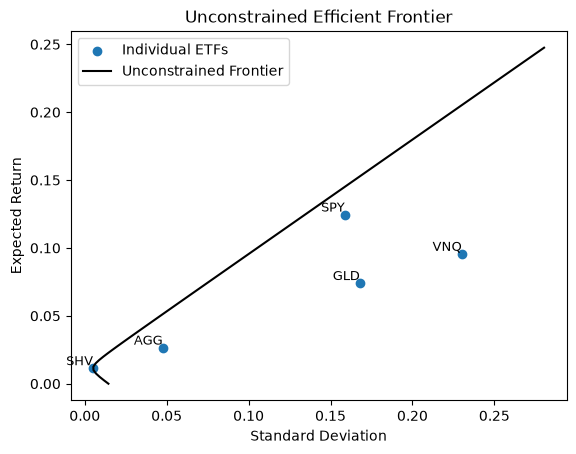

In [11]:
# Unconstrained Efficient Frontier for a range of target returns, we solve for portfolio weights that minimize variance without constraints on short sales.
target_returns = np.arange(0,0.25, 0.0025)
efficient_frontier_weights = []
portfolio_returns = []
portfolio_std_devs = []

for target_return in target_returns:
    constraints = [
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1},
        {'type': 'eq', 'fun': lambda w: np.dot(w, ER) - target_return}
    ]

    objective = lambda w: np.dot(w.T, np.dot(V, w))
    result = minimize(objective, x0=np.ones(len(ER))/len(ER), constraints=constraints, method='SLSQP', options={'maxiter': 100000, 'ftol': 1e-9})

    efficient_frontier_weights.append(result.x)
    portfolio_returns.append(np.dot(ER, result.x))
    portfolio_std_devs.append(np.sqrt(np.dot(result.x.T, np.dot(V, result.x))))

efficient_frontier_weights = np.array(efficient_frontier_weights).T

# Plot
plt.figure()

# Plot individual ETFs as scatter points with text labels
etfs_list = list(mean_annual.index) # Get the list of tickers from the index
plt.scatter(np.sqrt(np.diag(V)), ER, marker='o', label='Individual ETFs')

# Add text labels for individual ETFs
for i, ticker in enumerate(etfs_list):
    plt.text(np.sqrt(V[i, i]), ER[i], ticker, fontsize=9, ha='right', va='bottom')

#Plot the unconstrained frontier
plt.plot(portfolio_std_devs, portfolio_returns, 'k', label='Unconstrained Frontier')
plt.xlabel('Standard Deviation')
plt.ylabel('Expected Return')
plt.title('Unconstrained Efficient Frontier')
plt.legend()
plt.show()


# Constrained Efficient frontier

## Constrained 1 : no short sales
weights are non negative (0 <= w <= 1) and the sums of weights = 1.


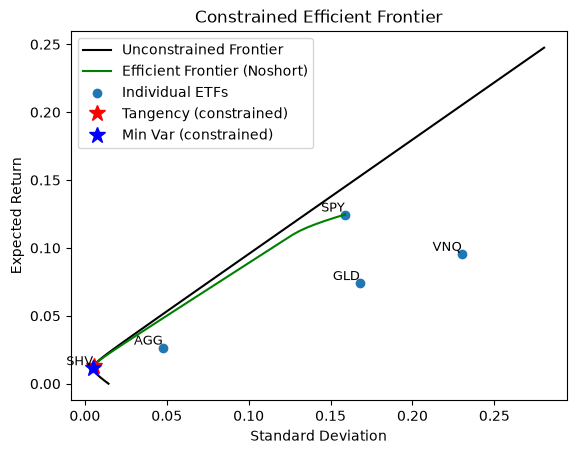

In [12]:
target_returns = np.arange(0, 0.25, 0.0025)
efficient_frontier_weights2 = []
portfolio_returns2 = []
portfolio_std_devs2 = []

for target_return in target_returns:
    constraints2 = [
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1},
        {'type': 'ineq', 'fun': lambda w: w},
        {'type': 'eq', 'fun': lambda w: np.dot(w, ER) - target_return}
    ]

    objective = lambda w: np.dot(w.T, np.dot(V, w))
    result = minimize(objective, x0=np.ones(len(ER))/len(ER), constraints=constraints2, method='SLSQP', options={'maxiter': 100000, 'ftol': 1e-9})

    efficient_frontier_weights2.append(result.x)
    portfolio_returns2.append(np.dot(ER, result.x))
    portfolio_std_devs2.append(np.sqrt(np.dot(result.x.T, np.dot(V, result.x))))

efficient_frontier_weights2 = np.array(efficient_frontier_weights2).T


#Plot the unconstrained frontier
plt.figure()
plt.plot(portfolio_std_devs, portfolio_returns, 'k', label='Unconstrained Frontier')
plt.plot(portfolio_std_devs2, portfolio_returns2, 'g', label='Efficient Frontier (Noshort)')

# Plot individual ETFs as scatter points with text labels
etfs_list = list(mean_annual.index) # Get the list of tickers from the index
plt.scatter(np.sqrt(np.diag(V)), ER, marker='o', label='Individual ETFs')

# Add text labels for individual ETFs
for i, ticker in enumerate(etfs_list):
    plt.text(np.sqrt(V[i, i]), ER[i], ticker, fontsize=9, ha='right', va='bottom')

plt.plot(s1, ER1, 'r*', markersize=12, label='Tangency (constrained)')
plt.plot(s2, ER2, 'b*', markersize=12, label='Min Var (constrained)')

plt.xlabel('Standard Deviation')
plt.ylabel('Expected Return')
plt.title('Constrained Efficient Frontier')
plt.legend()
plt.show()


## Constraint 2 : Min 20% of bonds and money market instrument
SHV + AGG >= 20%

Both constraints are implemented

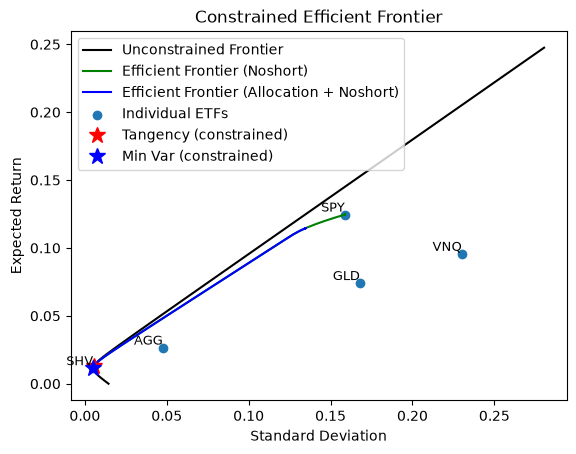

In [13]:
target_returns = np.arange(0, 0.25, 0.0025)
efficient_frontier_weights3 = []
portfolio_returns3 = []
portfolio_std_devs3 = []

# Index des ETF
agg_index = etfs.index('AGG')
shv_index = etfs.index('SHV')

for target_return in target_returns:
    constraints3 = [
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1},
        {'type': 'ineq', 'fun': lambda w: w},
        {'type': 'ineq', 'fun': lambda w: w[agg_index] + w[shv_index] - 0.2},
        {'type': 'eq', 'fun': lambda w: np.dot(w, ER) - target_return}
    ]

    objective = lambda w: np.dot(w.T, np.dot(V, w))
    result = minimize(objective, x0=np.ones(len(ER))/len(ER), constraints=constraints3, method='SLSQP', options={'maxiter': 100000, 'ftol': 1e-9})

    efficient_frontier_weights3.append(result.x)
    portfolio_returns3.append(np.dot(ER, result.x))
    portfolio_std_devs3.append(np.sqrt(np.dot(result.x.T, np.dot(V, result.x))))

efficient_frontier_weights3 = np.array(efficient_frontier_weights3).T


#Plot the unconstrained frontier
plt.figure()
plt.plot(portfolio_std_devs, portfolio_returns, 'k', label='Unconstrained Frontier')
plt.plot(portfolio_std_devs2, portfolio_returns2, 'g', label='Efficient Frontier (Noshort)')
plt.plot(portfolio_std_devs3, portfolio_returns3, 'b', label='Efficient Frontier (Allocation + Noshort)')

# Plot individual ETFs as scatter points with text labels
etfs_list = list(mean_annual.index) # Get the list of tickers from the index
plt.scatter(np.sqrt(np.diag(V)), ER, marker='o', label='Individual ETFs')

# Add text labels for individual ETFs
for i, ticker in enumerate(etfs_list):
    plt.text(np.sqrt(V[i, i]), ER[i], ticker, fontsize=9, ha='right', va='bottom')

plt.plot(s1, ER1, 'r*', markersize=12, label='Tangency (constrained)')
plt.plot(s2, ER2, 'b*', markersize=12, label='Min Var (constrained)')

plt.xlabel('Standard Deviation')
plt.ylabel('Expected Return')
plt.title('Constrained Efficient Frontier')
plt.legend()
plt.show()



# Optimal Portfolio allocation

## Find the 2 optimum portfolios
1. Minimum Sharp
2. Minimum Variance


In [14]:
from scipy.optimize import minimize

# Calculate mean returns and covariance matrix
mean_returns = returns.mean() * 12  # annualized
cov_matrix = returns.cov() * 12     # annualized

tickers = list(data.columns)

# Risk-free rate
rf = stats.loc['SHV', 'Annual Return']

# ---- Helper functions ----
def portfolio_performance(weights, mean_returns, cov_matrix):
    ret = np.dot(weights, mean_returns)
    vol = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    return ret, vol

def negative_sharpe_ratio(weights, mean_returns, cov_matrix, rf):
    ret, vol = portfolio_performance(weights, mean_returns, cov_matrix)
    return -(ret - rf) / vol

def portfolio_volatility(weights, mean_returns, cov_matrix):
    return portfolio_performance(weights, mean_returns, cov_matrix)[1]

# ---- Constraints ----
n_assets = len(tickers)
# Each assets between 0-100% (No short)
bounds = tuple((0,1) for _ in range(n_assets))
# Sum of weights = 1
constraints_sum = {'type': 'eq', 'fun': lambda x: np.sum(x) - 1}
# AGG (US bonds) + SHV (money market) >= 20%
constraint_agg_shv = {'type': 'ineq', 'fun': lambda x: x[tickers.index('AGG')] + x[tickers.index('SHV')] - 0.2}

constraints = (constraints_sum, constraint_agg_shv)


# ---- 1. Max Sharpe Ratio (Tangency Portfolio) ----
init_guess = n_assets * [1./n_assets]
tangency = minimize(negative_sharpe_ratio, init_guess, args=(mean_returns, cov_matrix, rf),
                    method='SLSQP', bounds=bounds, constraints=constraints)

tangency_weights = tangency.x

# ---- 2. Minimum Variance Portfolio ----
min_var = minimize(portfolio_volatility, init_guess, args=(mean_returns, cov_matrix),
                   method='SLSQP', bounds=bounds, constraints=constraints)

min_var_weights = min_var.x

# Print results
print("Tangency Portfolio:")
for i, w in enumerate(tangency_weights):
    print(f"{tickers[i]}: {w:.2%}")

print("\nMinimum Variance Portfolio:")
for i, w in enumerate(min_var_weights):
    print(f"{tickers[i]}: {w:.2%}")


Tangency Portfolio:
AGG: 10.85%
GLD: 23.65%
SHV: 9.15%
SPY: 56.35%
VNQ: 0.00%

Minimum Variance Portfolio:
AGG: 0.00%
GLD: 0.00%
SHV: 99.76%
SPY: 0.12%
VNQ: 0.12%


## Graphic representation

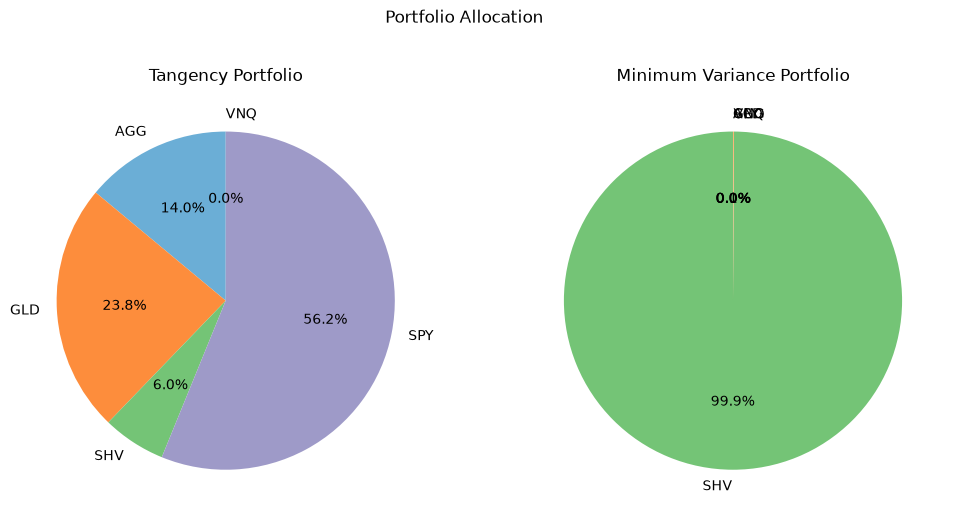

In [15]:

# Portfolio weights
tangency_alloc = {
    'AGG': 13.96,
    'GLD': 23.83,
    'SHV': 6.04,
    'SPY': 56.17,
    'VNQ': 0.00
}

min_var_alloc = {
    'AGG': 0.00,
    'GLD': 0.00,
    'SHV': 99.91,
    'SPY': 0.00,
    'VNQ': 0.09
}

# Labels and colors
labels = list(tangency_alloc.keys())
colors = ['#6baed6', '#fd8d3c', '#74c476', '#9e9ac8', '#fdae6b']

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Tangency Portfolio Pie
axes[0].pie(tangency_alloc.values(), labels=labels, autopct='%1.1f%%', startangle=90, colors=colors)
axes[0].set_title('Tangency Portfolio')

# Minimum Variance Pie
axes[1].pie(min_var_alloc.values(), labels=labels, autopct='%1.1f%%', startangle=90, colors=colors)
axes[1].set_title('Minimum Variance Portfolio')

plt.suptitle('Portfolio Allocation')
plt.show()



## Expected returns and Std deviation

In [16]:
# Inputs: mean_annual and cov_matrix defined from previous cells

# Portfolio weights
tangency_alloc = {
    'AGG': 13.96,
    'GLD': 23.83,
    'SHV': 6.04,
    'SPY': 56.17,
    'VNQ': 0.00
}
tangency_weights = np.array([0.1396, 0.2383, 0.0604, 0.5617, 0.0000])

min_var_alloc = {
    'AGG': 0.00,
    'GLD': 0.00,
    'SHV': 99.91,
    'SPY': 0.00,
    'VNQ': 0.09
}
min_var_alloc = np.array([0, 0, 99.91, 0, 0.09])


# Expected return
tangency_ER = tangency_weights @ ER
min_var_ER = min_var_weights @ ER

# volatility
tangency_std = np.sqrt(tangency_weights @ V @ tangency_weights)
min_var_std = np.sqrt(min_var_weights @ V @ min_var_weights)

s_tangency_min_var = tangency_weights @ V @ min_var_weights

print(f"Tangency Portfolio:\nReturn = {tangency_ER:.4f}, Std = {tangency_std:.4f}")
print(f"Min Variance Portfolio:\nReturn = {min_var_ER:.4f}, Std = {min_var_std:.4f}")


Tangency Portfolio:
Return = 0.0920, Std = 0.1041
Min Variance Portfolio:
Return = 0.0116, Std = 0.0051


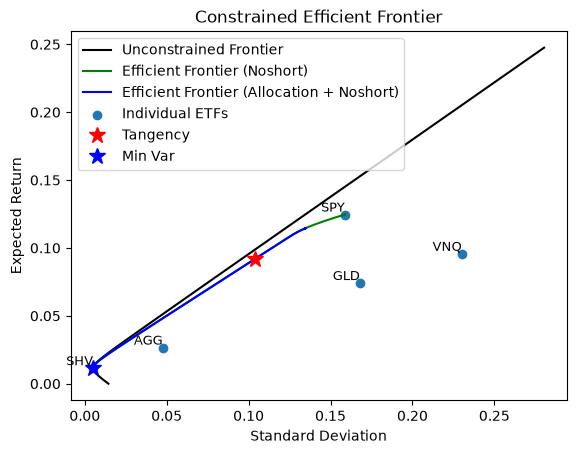

In [17]:
plt.figure()
plt.plot(portfolio_std_devs, portfolio_returns, 'k', label='Unconstrained Frontier')
plt.plot(portfolio_std_devs2, portfolio_returns2, 'g', label='Efficient Frontier (Noshort)')
plt.plot(portfolio_std_devs3, portfolio_returns3, 'b', label='Efficient Frontier (Allocation + Noshort)')

# Plot individual ETFs as scatter points with text labels
etfs_list = list(mean_annual.index) # Get the list of tickers from the index
plt.scatter(np.sqrt(np.diag(V)), ER, marker='o', label='Individual ETFs')

# Add text labels for individual ETFs
for i, ticker in enumerate(etfs_list):
    plt.text(np.sqrt(V[i, i]), ER[i], ticker, fontsize=9, ha='right', va='bottom')

plt.plot(tangency_std, tangency_ER, 'r*', markersize=12, label='Tangency')
plt.plot(min_var_std, min_var_ER, 'b*', markersize=12, label='Min Var')

plt.xlabel('Standard Deviation')
plt.ylabel('Expected Return')
plt.title('Constrained Efficient Frontier')
plt.legend()
plt.show()

## Monte Carlo Simulations

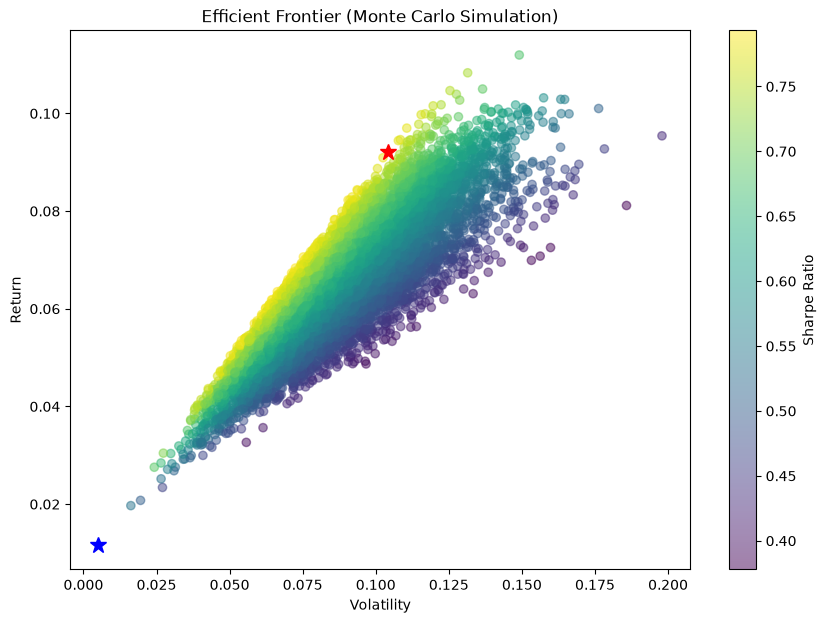

In [18]:
# ==== Inputs (Just a reminder, no need otherwise.) ====
mean_returns = np.array([0.124710, 0.095754, 0.074120, 0.026198, 0.010951])
std_devs = np.array([0.160995, 0.233817, 0.167876, 0.048336, 0.006180])
tickers = ['SPY', 'VNQ', 'GLD', 'AGG', 'SHV']
corr = np.array([
    [1.00, 0.65, 0.10, 0.15, 0.05],
    [0.65, 1.00, 0.20, 0.10, 0.02],
    [0.10, 0.20, 1.00, 0.05, 0.01],
    [0.15, 0.10, 0.05, 1.00, 0.20],
    [0.05, 0.02, 0.01, 0.20, 1.00]
])

# Risk-free rate = Annual Return of SHV
rf = mean_returns[tickers.index('SHV')]

# Covariance matrix
cov_matrix = corr * np.outer(std_devs, std_devs)



# ==== Monte Carlo Simulation ====
num_portfolios = 10000
results = np.zeros((3, num_portfolios))

for i in range(num_portfolios):
    weights = np.random.random(len(tickers))
    weights /= np.sum(weights)

    portfolio_return = np.dot(weights, mean_returns)
    portfolio_vol = np.sqrt(weights @ cov_matrix @ weights)
    sharpe_ratio = (portfolio_return - rf) / portfolio_vol

    results[0, i] = portfolio_vol
    results[1, i] = portfolio_return
    results[2, i] = sharpe_ratio

# ==== Plot Efficient Frontier ====
plt.figure(figsize=(10, 7))
plt.scatter(results[0], results[1], c=results[2], cmap='viridis', alpha=0.5)
plt.plot(tangency_std, tangency_ER, 'r*', markersize=12, label='Tangency')
plt.plot(min_var_std, min_var_ER, 'b*', markersize=12, label='Min Var')
plt.colorbar(label='Sharpe Ratio')
plt.xlabel('Volatility')
plt.ylabel('Return')
plt.title('Efficient Frontier (Monte Carlo Simulation)')
plt.show()

# Downside Risk

## Data


In [19]:
# Stats
summary_stats = pd.DataFrame({
    'Mean': mean_annual,
    'StdDev': vol_annual,
    'Skewness': returns.apply(skew, nan_policy='omit'),
    'Kurtosis': returns.apply(kurtosis, fisher=False, nan_policy='omit')  # Fisher=False gives normal kurtosis (3 for normal)
})
print(summary_stats)


            Mean    StdDev  Skewness  Kurtosis
Ticker                                        
AGG     0.026546  0.047537  0.333697  5.882738
GLD     0.074120  0.167876 -0.005134  3.294655
SHV     0.011402  0.005116  1.374481  3.732724
SPY     0.124544  0.158704 -0.599732  3.907059
VNQ     0.095629  0.229968 -0.608612  8.000404


### Correlation Matrix

SPY    | SPY - US Equities (S&P 500)
AGG    | AGG - US Bonds (Aggregate)
SHV    | SHV - Money Market
GLD    | GLD - Gold
VNQ    | VNQ - Real Estate


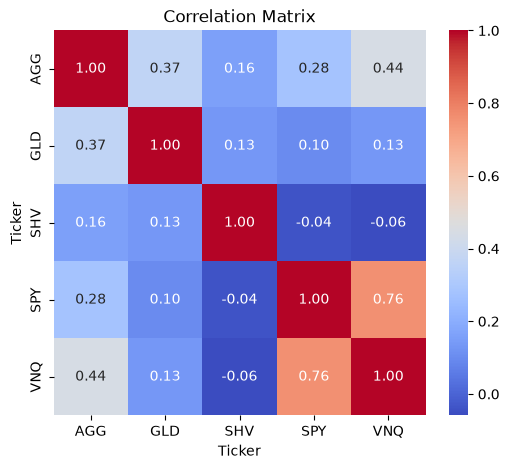

In [20]:
# Correlation matrix
corr = returns.corr()

#print une légende
for ticker, desc in names.items():
    print(f"{ticker:<6} | {desc}")

# Plot correlation heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()


### Monthly returns

In [21]:
#Monthly returns
print(returns)


Ticker           AGG       GLD       SHV       SPY       VNQ
Date                                                        
2008-02-01 -0.001601  0.052298  0.001908 -0.025843 -0.031814
2008-03-01  0.001298 -0.059992  0.003153 -0.008942  0.064853
2008-04-01  0.003275 -0.041588  0.000862  0.047662  0.063792
2008-05-01 -0.012652  0.009232  0.000145  0.015117 -0.002110
2008-06-01 -0.001849  0.045169  0.001874 -0.083576 -0.106153
...              ...       ...       ...       ...       ...
2024-08-01  0.014614  0.020922  0.004979  0.023366  0.052206
2024-09-01  0.013328  0.050889  0.004586  0.021005  0.032697
2024-10-01 -0.025187  0.042993  0.003576 -0.008923 -0.033566
2024-11-01  0.011110 -0.031241  0.003696  0.059633  0.042592
2024-12-01 -0.016934 -0.014088  0.004031 -0.024060 -0.083722

[203 rows x 5 columns]


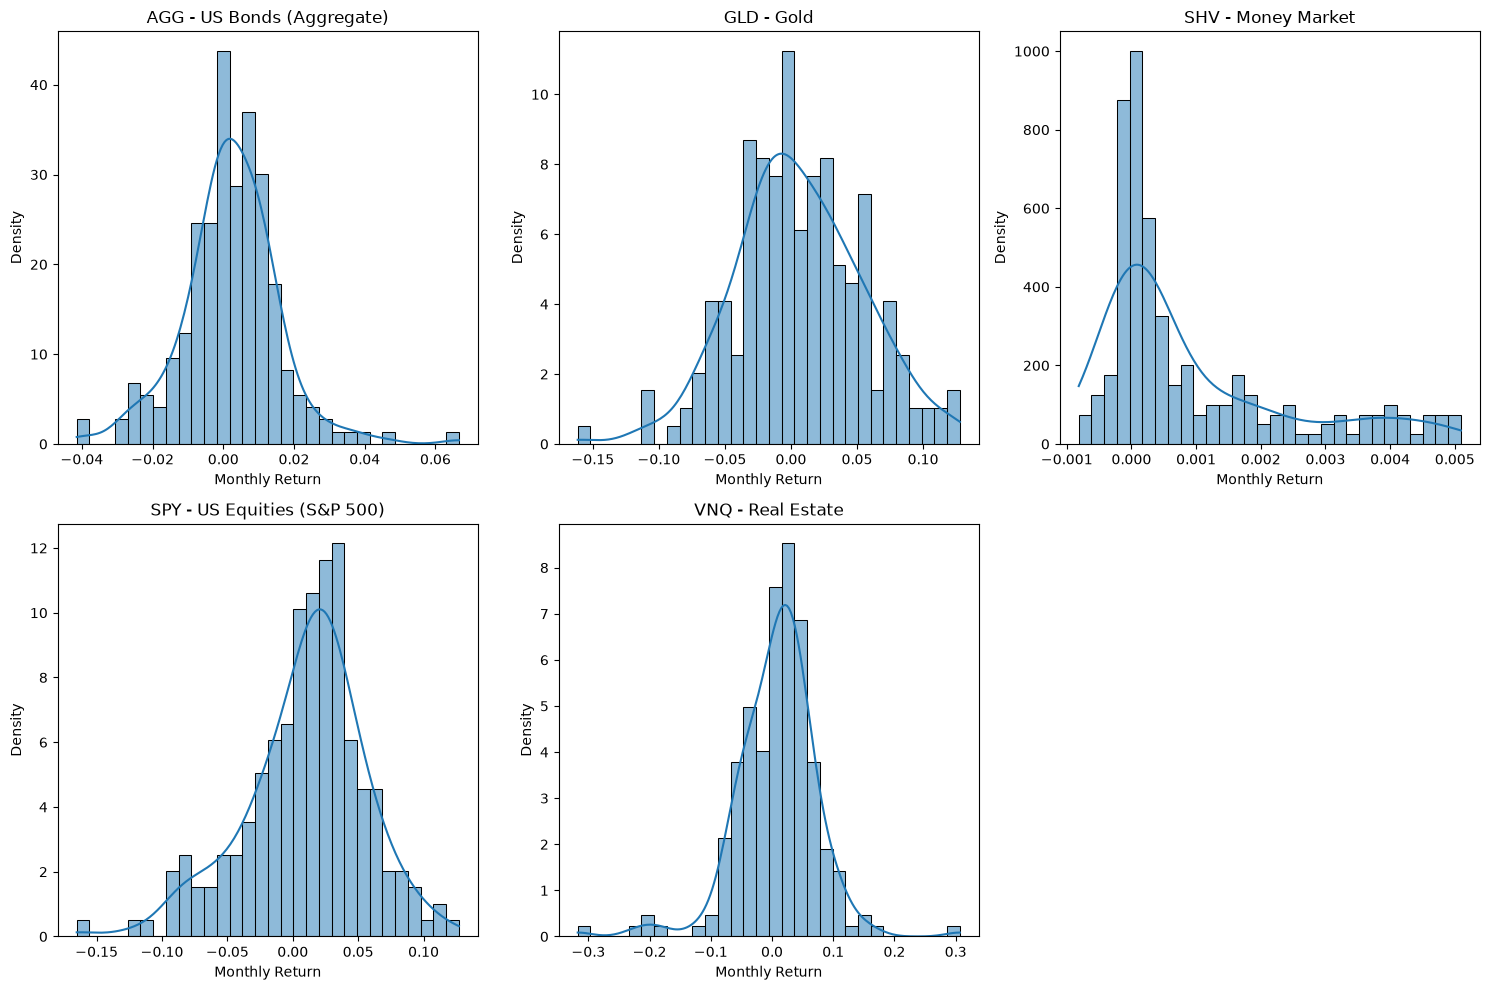

In [22]:
# Plot histograms of monthly returns for each ETF
plt.figure(figsize=(15, 10))
for i, ticker in enumerate(returns.columns):
    plt.subplot(2, 3, i + 1) # Adjust subplot grid based on number of ETFs
    sns.histplot(returns[ticker], bins=30, kde=True, stat='density')
    plt.title(f'{names[ticker]}')
    plt.xlabel('Monthly Return')
    plt.ylabel('Density')
plt.tight_layout()
plt.show()

## Simulate asset scenarios




We generate scenarios under two methods:

###1. **Normal**:
multivariate normal with empirical mean/cov, returns follow a Gaussian distribution

Pros:
- Simple and analytically tractable.
- Easy for generating many scenarios.

Cons:
- Underestimates extreme events (fat tails).
- Ignores skewness and kurtosis present in real markets.
- Future shocks (crises) may be much worse than predicted.


###2. **Empirical or bootstrap**:
 Sampling of historical returns, the future will look like the past, at least statistically. Just reuses historical returns with replacement.

Pros:
- Preserves all distributional properties of historical data (fat tails, skewness).
- No parametric assumption (non-parametric).

Cons:
- Limited to what happened historically (no “new” scenarios).
- If history is short or unrepresentative, this is risky.


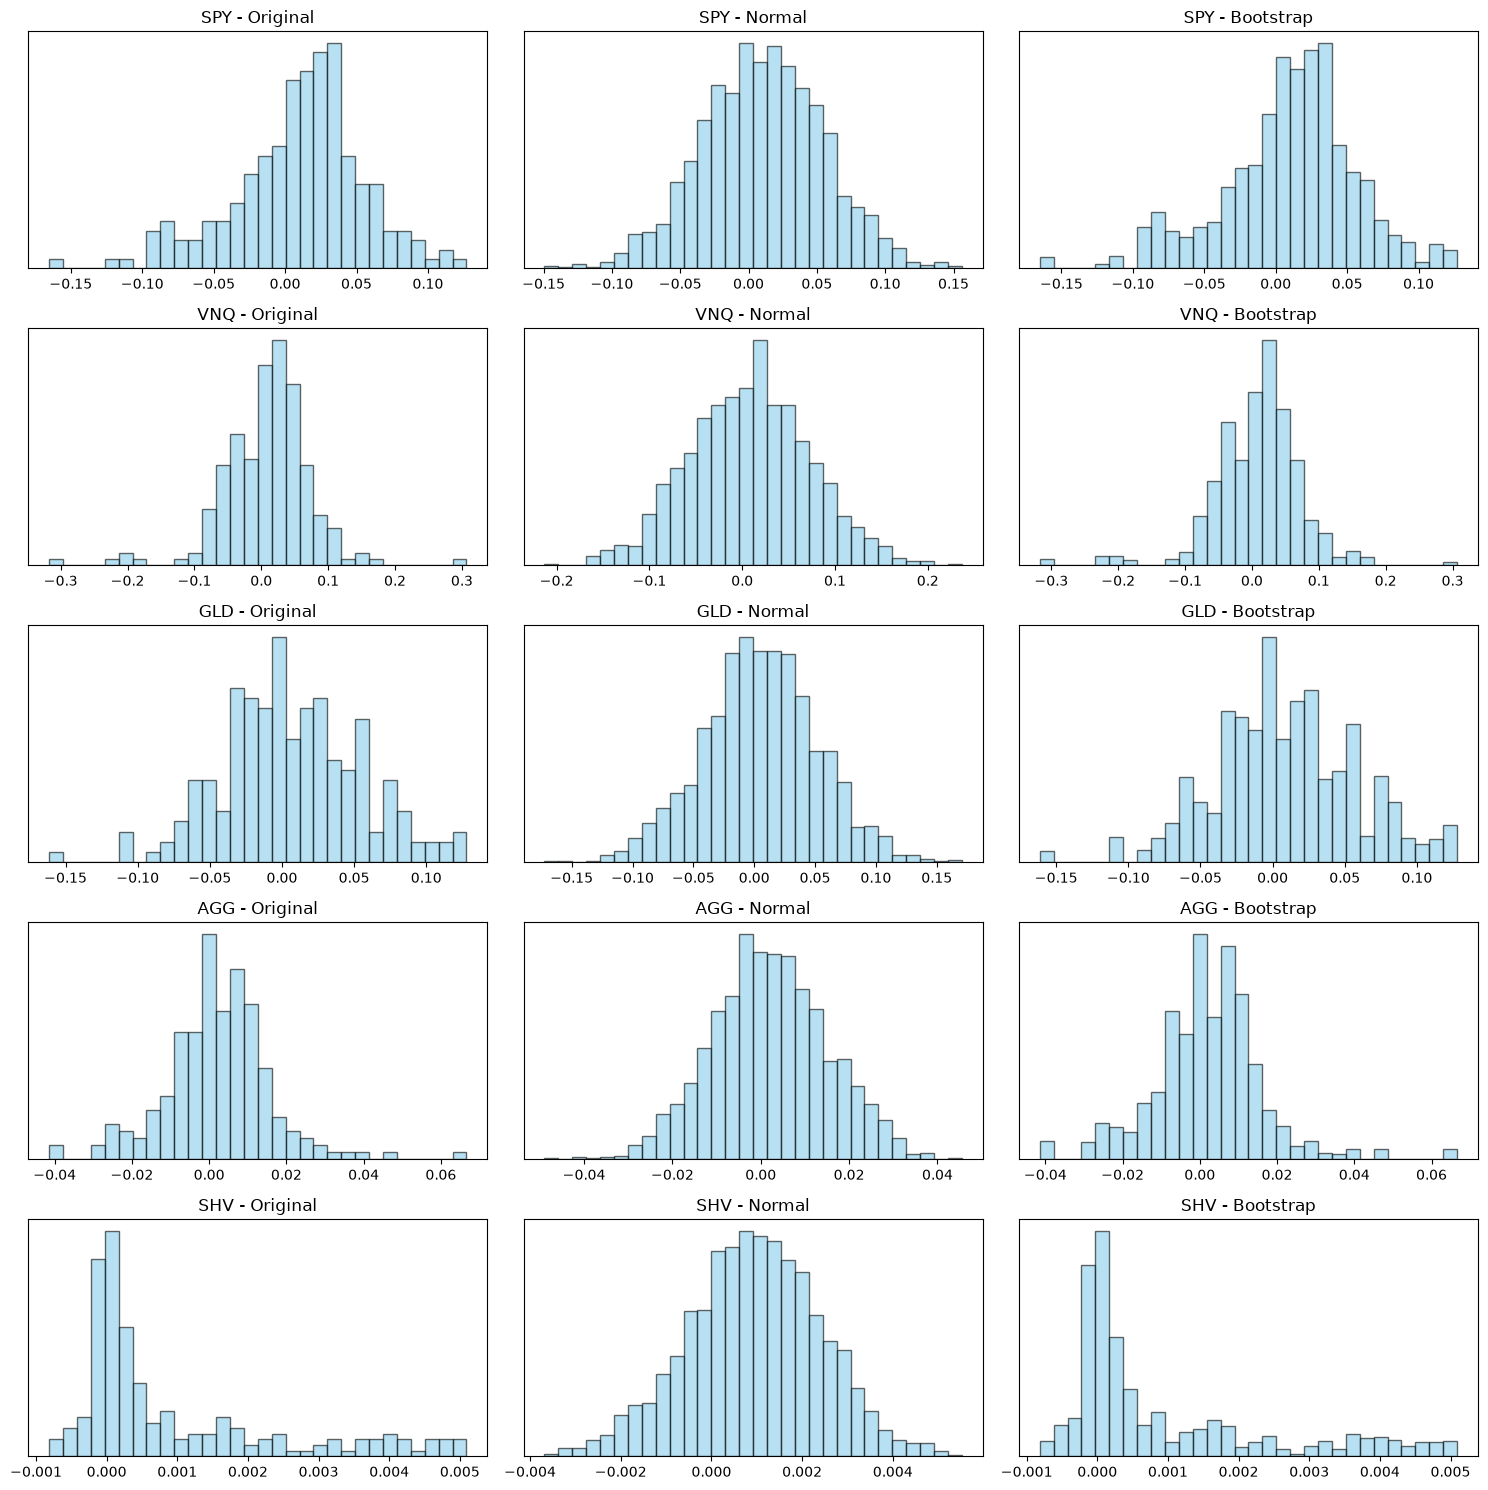

In [23]:

# We use Monthly returns

# Empirical average daily return for each assets
mu = returns.mean(axis=0)

#covariance matrix of the daily returns
sigma = np.cov(returns, rowvar=False)

# Number of scenarios
nScenario = 2000


#===== Normal scenario =====
scenarios_normal = np.random.multivariate_normal(mu, sigma, size=nScenario)
# Convert to pandas DataFrame and assign columns
scenarios_normal = pd.DataFrame(scenarios_normal, columns=returns.columns)

#===== Bootstrap scenario =====
idx = np.random.randint(0, returns.shape[0], size=(nScenario,))
scenarios_empirical = returns.iloc[idx, :]
# Convert to pandas DataFrame and assign columns
scenarios_empirical = pd.DataFrame(scenarios_empirical, columns=returns.columns)


#===== Histograms =====
methods = ['Original', 'Normal', 'Bootstrap']
scenarios_all = [returns, scenarios_normal, scenarios_empirical]

nAsset = len(tickers)
cols = len(methods)
rows = nAsset

fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3 * rows))

for i, tick in enumerate(tickers):
    for j, (method_name, scenario) in enumerate(zip(methods, scenarios_all)):
        ax = axes[i, j] if nAsset > 1 else axes[j]  # Handle 1-row case
        ax.hist(scenario[tick], bins=30, density=True, alpha=0.6, color='skyblue', edgecolor='black')
        ax.set_title(f"{tick} - {method_name}")
        ax.set_yticks([])  # Optional: remove y-axis ticks for cleaner look

plt.tight_layout()
plt.show()


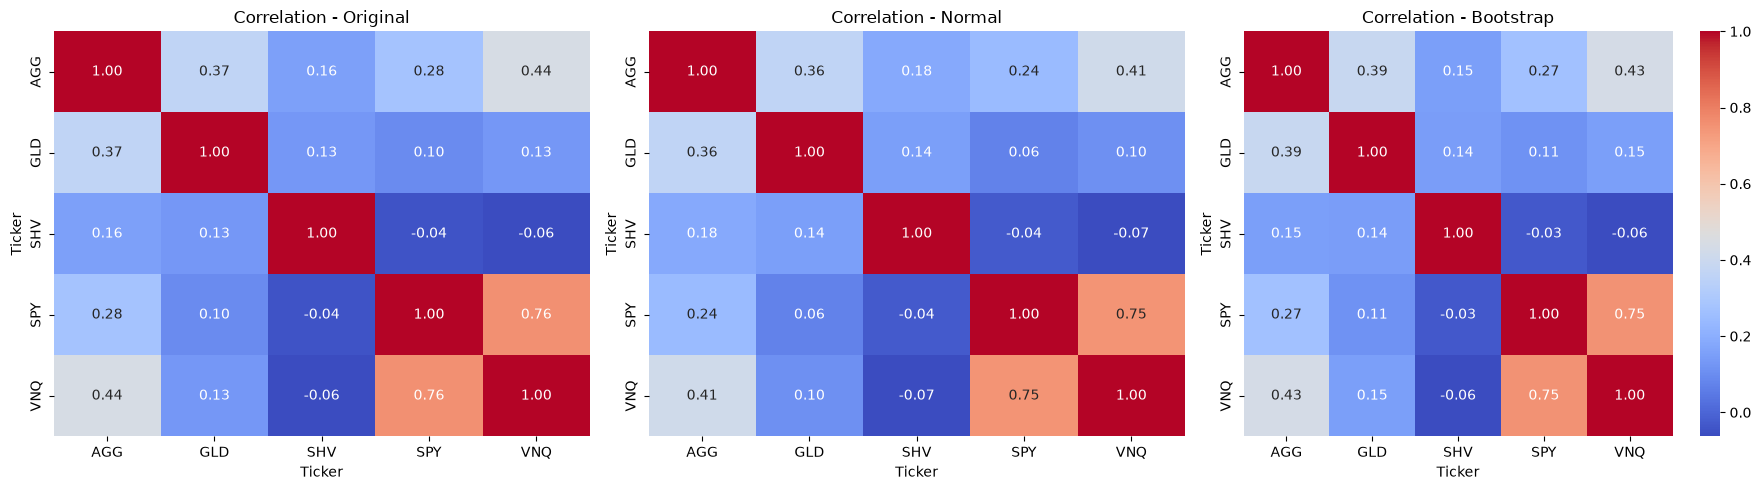

In [24]:
#===== Correlation Heatmap =====

methods = ['Original', 'Normal', 'Bootstrap']
scenarios_all = [returns, scenarios_normal, scenarios_empirical]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))  # 1 row, 3 columns

for j, (method_name, scenario) in enumerate(zip(methods, scenarios_all)):
    corr_matrix = scenario.corr()
    ax = axes[j]
    sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", ax=ax, cbar=j==2)
    ax.set_title(f"Correlation - {method_name}")

plt.tight_layout()
plt.show()

## VaR & CVaR of the tangency Portfolio

Step 1: Sort returns (ascending)

Step 2: Choose α, e.g: α = 95% → tail = 5% =>
95% confidence → worst 5% returns.

---

e.g.: For 10 observations → worst 1 return = -3.0%

Interpretation: “With 95% confidence, the loss will not exceed 3% in a month.”

---

VaR = the cutoff point (threshold of worst losses). *With X% confidence, what is the maximum loss we expect?*

CVaR = how bad the losses are on average beyond that point. *If we are in the worst X% of cases, what is the average loss?*




In [25]:
# Calculate monthly returns of Tangency portfolio
tangency_returns=returns @ tangency_weights
tangency_monthly_ER = tangency_returns.mean()
tangency_monthly_std = tangency_returns.std()

#faire le plt distribution des monthly returns du tangency


### Lower Partial Momentum
A lower partial moment (LPM) is a statistical measure used to quantify downside risk in finance. It focuses on returns below a specific target or threshold, unlike variance which treats positive and negative deviations symmetrically.

Defined as moments of the return distribution that consider only the left tail.

- LPM(0): Probability that returns < R₀ (usually 0%) → the probability of a loss.

- LPM(1): Average shortfall below R₀ -> how much you lose on average when returns are negative.

- LPM(2): Semi-variance → similar to variance but only for negative returns → used to measure downside volatility.

In [26]:
# Define a function that can be use with many parameters
def lower_partial_moment(returns, threshold=0.0, order=2):
    diff = threshold - returns
    if order == 0:
      return np.mean(returns < threshold)
    else:

      downside = np.where(diff > 0, diff, 0)
      return np.mean(downside**order)

#Compute the function
lpm_0 = lower_partial_moment(tangency_returns, threshold=0, order=0)
lpm_1 = lower_partial_moment(tangency_returns, threshold=0, order=1)
lpm_2 = lower_partial_moment(tangency_returns, threshold=0, order=2)

print(f"LPM(0): {lpm_0*100:.4f}% - Probability of a loss\nLPM(1): {lpm_1*100:.4f}% - Average Loss if returns are negative\nLPM(2): {lpm_2*100:.4f}% - Downside volatility")




LPM(0): 38.9163% - Probability of a loss
LPM(1): 0.8248% - Average Loss if returns are negative
LPM(2): 0.0356% - Downside volatility


### Parametric VaR
We assume normal distribution, With X% confidence, what is the maximum loss we expect?


In [27]:
def parametric_var(mean, std, alpha):
    z = {0.95: 1.645, 0.99: 2.33}
    return mean - z[alpha] * std


# α = 99%
var_param99 = parametric_var(tangency_monthly_ER, tangency_monthly_std, alpha=0.99)
print(f"Parametric VaR (99%): {var_param99:.4%}\nWith 99% confidence, your monthly portfolio loss will not exceed {-var_param99:.2%} under normal distribution assumption.\n")

# α = 95%
var_param95 = parametric_var(tangency_monthly_ER, tangency_monthly_std, alpha=0.95)
print(f"Parametric VaR (95%): {var_param95:.4%}\nWith 95% confidence, your monthly loss will not exceed {-var_param95:.2%}.")


Parametric VaR (99%): -6.2680%
With 99% confidence, your monthly portfolio loss will not exceed 6.27% under normal distribution assumption.

Parametric VaR (95%): -4.2104%
With 95% confidence, your monthly loss will not exceed 4.21%.


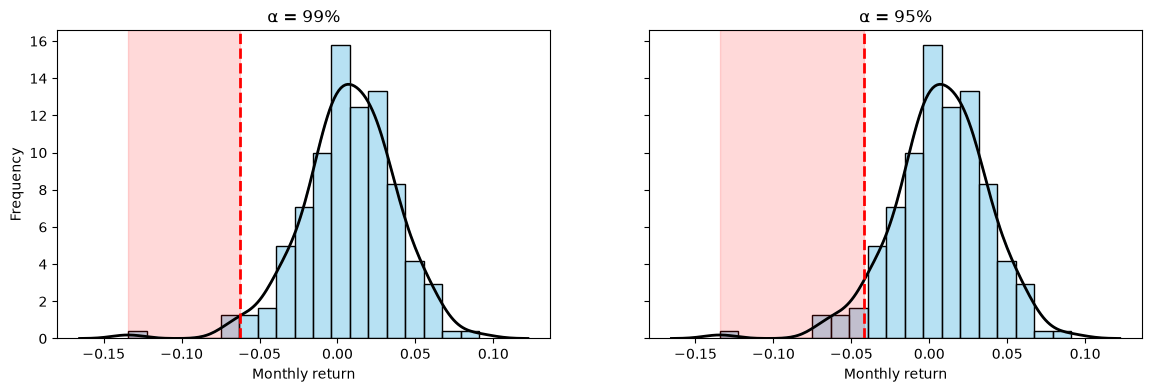

In [28]:
#===== Histograms =====
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)


##### Subplot 1 : VaR 99% #####
sns.histplot(tangency_returns, kde=True, color="skyblue", edgecolor="black",
             linewidth=1, alpha=0.6, stat="density", ax=axes[0]) #stat=Density, pour faire correspondre les Kde
sns.kdeplot(tangency_returns, color="black", linewidth=2, ax=axes[0])

# Ligne verticale pour VaR
axes[0].axvline(x=var_param99, color='red', linestyle='--', linewidth=2, label=f'VaR 99% ({var_param99:.2%})')
# Zone rouge à gauche de la VaR
axes[0].axvspan(xmin=tangency_returns.min(), xmax=var_param99, color='red', alpha=0.15)

axes[0].set_xlabel('Monthly return')
axes[0].set_ylabel('Frequency')
axes[0].set_title('α = 99%')


##### Subplot 2 : VaR 95% #####
sns.histplot(tangency_returns, kde=True, color="skyblue", edgecolor="black",
             linewidth=1, alpha=0.6, stat="density", ax=axes[1]) #stat=Density, pour faire correspondre les Kde
sns.kdeplot(tangency_returns, color="black", linewidth=2, ax=axes[1])

# Ligne verticale pour VaR
axes[1].axvline(x=var_param95, color='red', linestyle='--', linewidth=2, label=f'VaR 95% ({var_param95:.2%})')
# Zone rouge à gauche de la VaR
axes[1].axvspan(xmin=tangency_returns.min(), xmax=var_param95, color='red', alpha=0.15)

axes[1].set_xlabel('Monthly return')
axes[1].set_ylabel('Frequency')
axes[1].set_title('α = 95%')


plt.show()



### Historical VaR
Compute Historical VaR (percentile)
With X% confidence, what is the maximum loss we expect?

In [29]:
def historical_var(returns, alpha):
    return np.percentile(returns, (1 - alpha) * 100)


# α = 99%
var_hist99 = historical_var(tangency_returns, alpha=0.99)
print(f"Historical VaR (99%): {var_hist99:.4%}\nWith 99% confidence, your monthly loss will not exceed {-var_hist99:.2%}.\n")


# α = 95%
var_hist95 = historical_var(tangency_returns, alpha=0.95)
print(f"Historical VaR (95%): {var_hist95:.4%}\nWith 95% confidence, your monthly loss will not exceed {-var_hist95:.2%}.")


Historical VaR (99%): -6.4573%
With 99% confidence, your monthly loss will not exceed 6.46%.

Historical VaR (95%): -4.0877%
With 95% confidence, your monthly loss will not exceed 4.09%.


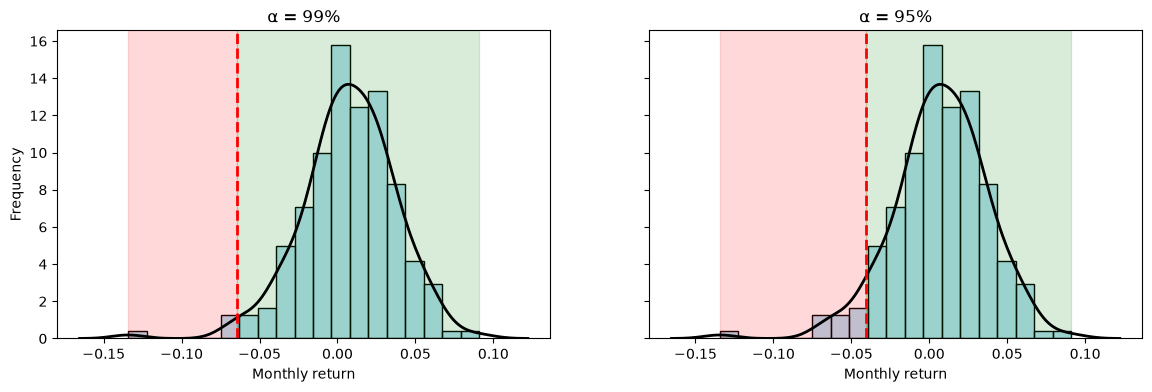

In [30]:
#===== Histograms =====
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)


##### Subplot 1 : VaR 99% #####
sns.histplot(tangency_returns, kde=True, color="skyblue", edgecolor="black",
             linewidth=1, alpha=0.6, stat="density", ax=axes[0]) #stat=Density, pour faire correspondre les Kde
sns.kdeplot(tangency_returns, color="black", linewidth=2, ax=axes[0])

# Ligne verticale pour VaR
axes[0].axvline(x=var_hist99, color='red', linestyle='--', linewidth=2, label=f'VaR 99% ({var_hist99:.2%})')
# Zone rouge à gauche de la VaR
axes[0].axvspan(xmin=tangency_returns.min(), xmax=var_hist99, color='red', alpha=0.15)
axes[0].axvspan(xmin=var_hist99, xmax=tangency_returns.max(), color='green', alpha=0.15)


axes[0].set_xlabel('Monthly return')
axes[0].set_ylabel('Frequency')
axes[0].set_title('α = 99%')


##### Subplot 2 : VaR 95% #####
sns.histplot(tangency_returns, kde=True, color="skyblue", edgecolor="black",
             linewidth=1, alpha=0.6, stat="density", ax=axes[1]) #stat=Density, pour faire correspondre les Kde
sns.kdeplot(tangency_returns, color="black", linewidth=2, ax=axes[1])

# Ligne verticale pour VaR
axes[1].axvline(x=var_hist95, color='red', linestyle='--', linewidth=2, label=f'VaR 95% ({var_hist95:.2%})')
# Zone rouge à gauche de la VaR
axes[1].axvspan(xmin=tangency_returns.min(), xmax=var_hist95, color='red', alpha=0.15)
axes[1].axvspan(xmin=var_hist95, xmax=tangency_returns.max(), color='green', alpha=0.15)

axes[1].set_xlabel('Monthly return')
axes[1].set_ylabel('Frequency')
axes[1].set_title('α = 95%')


plt.show()

### Historical CVaR
Expected Shortfall =
    
If we are in the worst X% of cases, what is the average loss?

In [31]:
def historical_cvar(returns, alpha):
    var_level = historical_var(returns, alpha)
    return returns[returns < var_level].mean()


# α = 99%
cvar_hist99 = historical_cvar(tangency_returns, alpha=0.99)
print(f"Historical CVaR (99%): {cvar_hist99:.4%}\nAverage loss of approximately {-cvar_hist99:.2%} in the worst 99% of cases.\n")

# α = 95%
cvar_hist95 = historical_cvar(tangency_returns, alpha=0.95)
print(f"Historical CVaR (95%): {cvar_hist95:.4%}\nAverage loss of approximately {-cvar_hist95:.2%} in the worst 95% of cases.")

Historical CVaR (99%): -9.0015%
Average loss of approximately 9.00% in the worst 99% of cases.

Historical CVaR (95%): -6.2023%
Average loss of approximately 6.20% in the worst 95% of cases.


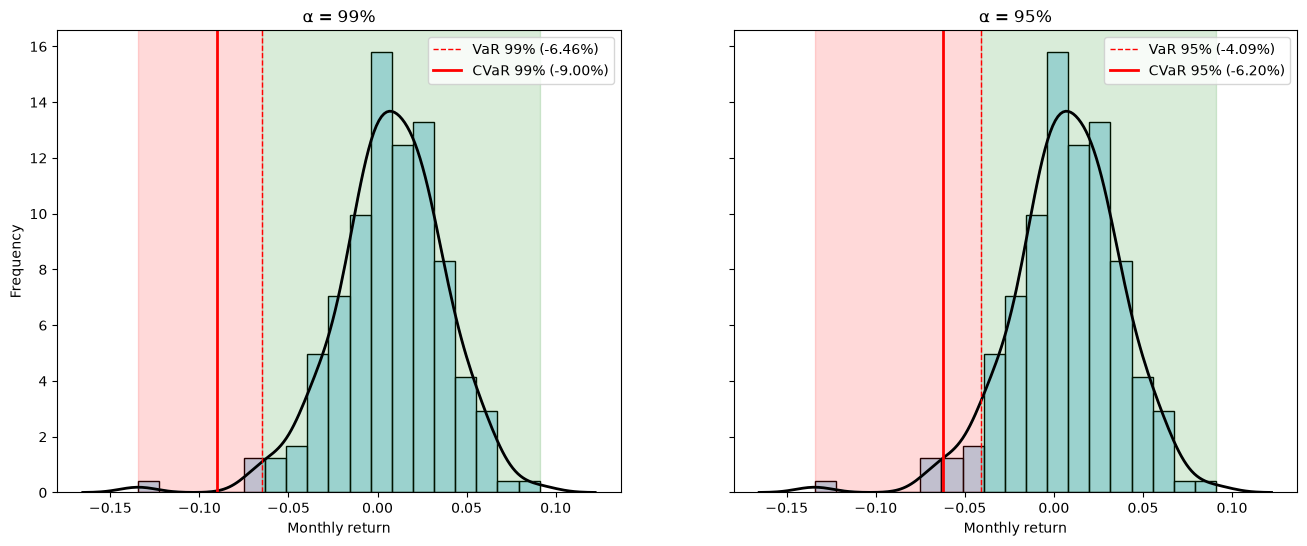

In [32]:
#===== Histograms =====
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)


##### Subplot 1 : VaR 99% #####
sns.histplot(tangency_returns, kde=True, color="skyblue", edgecolor="black",
             linewidth=1, alpha=0.6, stat="density", ax=axes[0]) #stat=Density, pour faire correspondre les Kde
sns.kdeplot(tangency_returns, color="black", linewidth=2, ax=axes[0])

# Ligne verticale pour VaR
axes[0].axvline(x=var_hist99, color='red', linestyle='--', linewidth=1, label=f'VaR 99% ({var_hist99:.2%})')
# Ligne verticale pour CVaR
axes[0].axvline(x=cvar_hist99, color='red', linestyle='-', linewidth=2, label=f'CVaR 99% ({cvar_hist99:.2%})')
# Zone rouge à gauche de la VaR
axes[0].axvspan(xmin=tangency_returns.min(), xmax=var_hist99, color='red', alpha=0.15)
axes[0].axvspan(xmin=var_hist99, xmax=tangency_returns.max(), color='green', alpha=0.15)


axes[0].set_xlabel('Monthly return')
axes[0].set_ylabel('Frequency')
axes[0].set_title('α = 99%')
axes[0].legend(loc='upper right')

##### Subplot 2 : VaR 95% #####
sns.histplot(tangency_returns, kde=True, color="skyblue", edgecolor="black",
             linewidth=1, alpha=0.6, stat="density", ax=axes[1]) #stat=Density, pour faire correspondre les Kde
sns.kdeplot(tangency_returns, color="black", linewidth=2, ax=axes[1])

# Ligne verticale pour VaR
axes[1].axvline(x=var_hist95, color='red', linestyle='--', linewidth=1, label=f'VaR 95% ({var_hist95:.2%})')
# Ligne verticale pour CVaR
axes[1].axvline(x=cvar_hist95, color='red', linestyle='-', linewidth=2, label=f'CVaR 95% ({cvar_hist95:.2%})')
# Zone rouge à gauche de la VaR
axes[1].axvspan(xmin=tangency_returns.min(), xmax=var_hist95, color='red', alpha=0.15)
axes[1].axvspan(xmin=var_hist95, xmax=tangency_returns.max(), color='green', alpha=0.15)

axes[1].set_xlabel('Monthly return')
axes[1].set_ylabel('Frequency')
axes[1].set_title('α = 95%')
axes[1].legend(loc='upper right')


plt.show()

 # CVaR Optimization


Find the portfolio with the maximum expected return subject to a 1-month maximum value at risk constraint of 3% with a 99% confidence on the portfolio return.

 Define a function to minimize CVaR at confidence level using the Rockafellar-Uryasev linear programming formulation. The objective function of the minimization program is:

$$
CVaR_{\alpha} = \theta + \frac{1}{n(1 - \alpha)} \sum_{i=1}^{n} \max(0, \text{loss}_i - \theta)
$$



CVaR portfolio optimization with expected return constraint.

### CVaR Optimization Function
Rockafellar-Uryasev


    Parameters:
    - scenarios: (n x m) array or DataFrame of return scenarios
    - mu: (m,) array or Series of expected returns
    - target_return: desired minimum portfolio expected return
    - alpha: CVaR confidence level

    Returns:
    - w_opt: optimized portfolio weights
    - cvar_value: estimated CVaR value at the optimum
   


In [33]:
def optimize_cvar(scenarios, mu, target_return, alpha):
  n, m = scenarios.shape

  # Define optimization variables
  w = cp.Variable(m) # weights
  z = cp.Variable(n) # excess loss beyond VaR
  theta = cp.Variable() # VaR threshold

  # Portfolio loss in each scenario
  loss = - scenarios @ w # a negative return is a positive loss

  # Constraints
  constraints = [
      cp.sum(w) == 1,           # Fully invested
      w >= 0,                   # No short-selling
      mu @ w >= target_return,  # Return constraint
      z >= loss - theta,
      z >= 0 # this constraint and the previous are equivalent to z = max(0, loss - theta) given that the objective of the minimizazion depends positively on theta
  ]

  # CVaR objective
  obj = cp.Minimize(theta + cp.sum(z) / (n * (1 - alpha)))

  # Solve
  prob = cp.Problem(obj, constraints)
  prob.solve()

  # Compute final CVaR value (redundant but transparent)
  cvar = theta.value + np.sum(np.maximum(loss.value - theta.value, 0)) / (n * (1 - alpha))

  return w.value, cvar, theta.value


### Compute CVaR portfolio weights
Find the portfolio with the maximum expected return subject to a 1-month maximum value at risk constraint of 3% with a 99% confidence on the portfolio return.

In [34]:
# ------------------------------------------------------------------
# 0.  PREPARE INPUTS
# ------------------------------------------------------------------
alpha   = 0.99                                 # 99 % confidence
mu_vec  = mu.values                            # 1×N vector of exp. monthly returns
scen_np = scenarios_empirical.values           # T×N matrix of monthly returns
#   ↳ if you also want the normal‑simulated frontier, call the
#     function again with  `scenarios_normal.values`

# Build a grid of 10 evenly–spaced target returns
targets  = np.linspace(mu_vec.min(), mu_vec.max(), 10)

# Containers to store results
weights_emp   = []      # list of weight vectors (empirical scenarios)
cvar_emp      = []      # corresponding CVaR values
theta_emp     = []      # VaR auxiliary variable (θ)

# ------------------------------------------------------------------
# 1.  LOOP OVER TARGET RETURNS  ➜  OPTIMISE CVaR FOR EACH
# ------------------------------------------------------------------
for tr in targets:
    w_opt, cvar_opt, theta_opt = optimize_cvar(
        scen_np, mu_vec, tr, alpha
    )
    weights_emp.append(w_opt)
    cvar_emp.append(cvar_opt)
    theta_emp.append(theta_opt)

# ------------------------------------------------------------------
# 2.  CONVERT TO CLEAN DATAFRAMES  (easy to inspect / plot)
# ------------------------------------------------------------------
weights_emp_df = pd.DataFrame(
    np.column_stack(weights_emp),
    index = tickers,            # ETF tickers on rows
    columns = [f"Target {round(t,4):.4f}" for t in targets]
)

cvar_emp_ser = pd.Series(cvar_emp, index=weights_emp_df.columns, name="CVaR99")

# Quick check
print("===== Weights (empirical CVaR‑frontier) =====")
display(weights_emp_df.round(4).T)      # transpose for readability
print("\n===== CVaR (99 %) for each target =====")
print(cvar_emp_ser.apply(lambda x: f"{x:.2%}"))
print("\n===== Mu.describe =====")
print(mu.describe())


NameError: name 'cp' is not defined

In [ ]:
# Calculate the returns of the portfolios
returns_portfolios = mu @ weights_emp_df

# Print the results
print("Portfolio Returns:")
print(returns_portfolios)


Portfolio Returns:
Target 0.0009    0.005982
Target 0.0019    0.005552
Target 0.0029    0.005603
Target 0.0039    0.005349
Target 0.0049    0.005094
Target 0.0059    0.004840
Target 0.0069    0.004586
Target 0.0079    0.004143
Target 0.0088    0.003150
Target 0.0098    0.002157
dtype: float64


In [ ]:
# Build table
table = pd.DataFrame(weights_emp, columns=tickers)  # chaque ligne = poids pour un target
table["Target Return"] = [f"Target {t:.2%}" for t in targets]
table["CVaR (99%)"] = cvar_emp
table["Expected Return"] = returns_portfolios.values
table = table[["Target Return", "CVaR (99%)", "Expected Return"] + tickers]  # réorganise les colonnes

# Data

table["CVaR (99%)"] = table["CVaR (99%)"].apply(lambda x: f"{x:.2%}")
table["Expected Return"] = table["Expected Return"].apply(lambda x: f"{x:.3%}")
table[tickers] = table[tickers].applymap(lambda x: f"{x:.2%}")


display(table)

/tmp/ipython-input-381326126.py:12: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  table[tickers] = table[tickers].applymap(lambda x: f"{x:.2%}")


,Target Return,CVaR (99%),Expected Return,SPY,VNQ,GLD,AGG,SHV
0,Target 0.09%,0.10%,0.598%,0.00%,0.33%,99.67%,0.00%,0.00%
1,Target 0.19%,1.46%,0.555%,0.00%,0.00%,88.89%,11.11%,0.00%
2,Target 0.29%,3.03%,0.560%,10.80%,0.00%,68.49%,20.71%,-0.00%
3,Target 0.39%,4.68%,0.535%,14.67%,0.00%,54.05%,31.28%,-0.00%
4,Target 0.49%,6.32%,0.509%,18.54%,0.00%,39.61%,41.85%,-0.00%
5,Target 0.59%,7.96%,0.484%,22.40%,0.00%,25.18%,52.42%,-0.00%
6,Target 0.69%,9.61%,0.459%,26.27%,0.00%,10.74%,62.99%,-0.00%
7,Target 0.79%,11.26%,0.414%,25.84%,0.00%,0.00%,74.16%,0.00%
8,Target 0.88%,12.93%,0.315%,12.92%,0.00%,0.00%,87.08%,-0.00%
9,Target 0.98%,14.60%,0.216%,-0.00%,0.00%,0.00%,100.00%,-0.00%


**Conclusion**:
- Target 0.xx% is the goal per month
- Expected return is what we ll get if everything goes well.

*Expected Return is the actual result of the optimization — sometimes it’s higher than the target, sometimes lower.*

- CVaR 99% is the extreme risk, in 1% of cases, we loose 0.10%

So we take CVaR ≤ 3%, we are left with portfolios 0, 1, 2.

And the max expected return is portfolio 0 with 0.598%	per month.

# Black-Litterman Method


❗ Problem with traditional mean-variance optimization:
Sample mean returns (from historical data) are:

- Noisy: Short time series → high variance.

- Unstable: Small changes in input → huge shifts in portfolio weights.

- Biased: High returns in sample may be due to luck, not true performance.

➡️ Result: You end up with extreme, concentrated portfolios that are not robust.

---

✅ Black-Litterman :
1. Starts with a neutral, market equilibrium view — like assuming the market portfolio is optimal (from CAPM).

2. Allows you to incorporate your own views (e.g., “I believe tech will outperform energy by 3%”) in a structured way.

3. Blends the equilibrium returns with your subjective views, weighted by your confidence in those views.

🧠 Intuition: Think of it like a Bayesian update:

Prior = Implied returns from the market.

New information = Your views.

Posterior = New expected returns you’ll use for optimization.

### 0. Pepare the inputs

In [ ]:
#Tickers
tickers

#monthly returns
returns

#covariance matrix: Σ
cov_matrix

# historical anualized returns
mean_annual


,0
Ticker,
AGG,0.026198
GLD,0.074120
SHV,0.010951
SPY,0.124710
VNQ,0.095754


### 2. Implied returns



Π = λ ⋅ Σ ⋅ w_mkt


🔧 Paramètres :
- 𝛱 : les rendements implicites "neutres"
- 𝜆 : coeff d'aversion au risque
- *w_mkt* = poids de marché pour chaque ETF (tu peux l’inventer ou le prendre de Vanguard, ex. SPY=60%, AGG=20%, etc.)
- Σ = covariance matrix

Implied return: returns needed by each assets class to achieve the goal.

(here VNQ is more risky, so it needs more returns compared to SPY)

In [ ]:
# Market weight vector
w_mkt = np.array([0.60, 0.20, 0.10, 0.05, 0.05])  # [SPY, AGG, SHV, GLD, VNQ]

#Risk aversion
λ=2.5 #typical value for risk aversion


#Compute implied returns (pi)
pi = λ * cov_matrix @ w_mkt

#make it readable
pi_series = pd.Series(pi, index=tickers)
print(pi_series.map('{:.2%}'.format))

SPY    5.19%
VNQ    6.61%
GLD    1.51%
AGG    0.27%
SHV    0.01%
dtype: object


### 3. Integrate my views

To adjust the **implied returns** from the market equilibrium (denoted by **Π**), we incorporate our own **subjective views** about certain assets or combinations of assets using three key components:

- **P**: The **pick matrix** — size: *(number of views) × (number of assets)*. Each row represents a view (which assets are involved and how).
- **Q**: A vector containing the **expected return** for each view.
- **Ω**: A diagonal matrix representing the **uncertainty (confidence)** in each view. Lower values in Ω mean higher confidence.

---

📘 Interpretation Table

| Element           | Description                                              | Example                                                              |
|-------------------|----------------------------------------------------------|----------------------------------------------------------------------|
| $\mathbf{P}$       | Matrix of views (*views × assets*)                      | "SPY will outperform AGG" → `[1, -1, 0, 0, 0]`                        |
| $\mathbf{Q}$       | Expected return from each view                          | "SPY will outperform AGG by 2%" → `Q = [0.02]`                        |
| $\mathbf{\Omega}$  | Confidence matrix (diagonal)                            | High confidence → `Ω = [[0.0001]]`                                   |


→ Forte confiance ? Ω = [[0.0001]]

→ Moyenne confiance ? Ω = [[0.0005]]

→ Faible confiance ? Ω = [[0.001]]


In [ ]:
### MY TAKE IS ###
# SPY (stocks) will outperfom  GLD (Gold) by 2%
P = np.array([[1, 0, 0, -1, 0]])

Q = np.array([0.02])

Ω = np.array([[0.0005]])

#Rem: use matrix

### 4. Black Litterman posterior expected retunrs


The combined Black-Litterman posterior expected returns **μ<sub>BL</sub>** are calculated as:

$$
\mu_{BL} = \left[(\tau \Sigma)^{-1} + P^\top \Omega^{-1} P \right]^{-1} \left[(\tau \Sigma)^{-1} \Pi + P^\top \Omega^{-1} Q\right]
$$

Where:

- **Π = λ Σ w<sub>mkt</sub>** is the implied return from market equilibrium.
- **τ** is a scalar (typically small, e.g., 0.025–0.05) representing uncertainty in the prior covariance matrix **Σ**.




If very high confidence (Ω -> 0) = Solution is closer to Q

If weak confidence (higher Ω) = Solution is closer to pi

τ moderate the confidence in the historical returns estimation.

In [ ]:
τ = 0.05
tau = τ
omega = Ω


#### Calcul ####
# Inverses
tau_sigma_inv = np.linalg.inv(tau * cov_matrix)
omega_inv = np.linalg.inv(omega)

# Posterior expected returns
middle = np.linalg.inv(tau_sigma_inv + P.T @ omega_inv @ P)
rhs = tau_sigma_inv @ pi + P.T @ omega_inv @ Q
posterior_returns = middle @ rhs

# print and comparaison
posterior_series = pd.Series(posterior_returns.flatten(), index=tickers)

print("\nimplied Returns (pi):")
print(pi_series.map('{:.2%}'.format))
print("\nPosterior Black-Litterman:")
print(posterior_series.map('{:.2%}'.format))


implied Returns (pi):
SPY    5.19%
VNQ    6.61%
GLD    1.51%
AGG    0.27%
SHV    0.01%
dtype: object

Posterior Black-Litterman:
SPY    3.18%
VNQ    4.72%
GLD    1.32%
AGG    0.37%
SHV    0.01%
dtype: object


# Reoptimize with the new BLμ


## Efficent Frontier

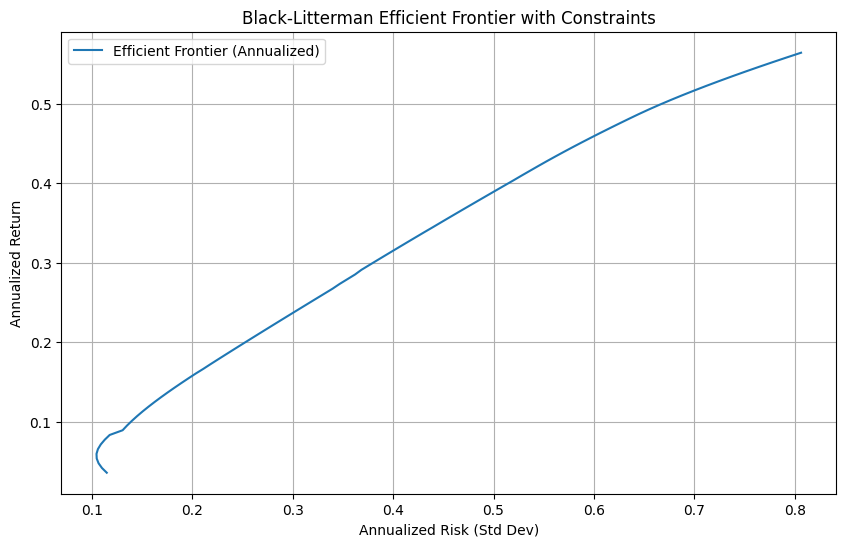

In [ ]:
#Tickers
tickers
n = len(tickers)

#covariance matrix: Σ
cov_matrix

# historical anualized returns
posterior_series


#### Fonctions de base ####
def portfolio_variance(weights, cov_matrix):
    return weights.T @ cov_matrix @ weights

def portfolio_return(weights, returns):
    return weights @ returns

def constraint_sum_to_one(weights):
    return np.sum(weights) - 1

def constraint_min_agg_shv(weights):
    return weights[1] + weights[2] - 0.2  # AGG + SHV ≥ 20%


#### Paramètres d'optimisation ####
bounds = [(0, 1) for _ in range(n)]  # no short
init_guess = np.ones(n) / n

#### Compute efficient frontier ####
target_returns = np.linspace(0.001, 0.05, 100)
efficient_risks = []

for target in target_returns:
    constraints = [
        {'type': 'eq', 'fun': constraint_sum_to_one},
        {'type': 'ineq', 'fun': constraint_min_agg_shv},
        {'type': 'eq', 'fun': lambda w, target=target: portfolio_return(w, posterior_returns) - target}
    ]

    result = minimize(portfolio_variance,
                      init_guess,
                      args=(cov_matrix,),
                      method='SLSQP',
                      bounds=bounds,
                      constraints=constraints)

    if result.success:
        risk = np.sqrt(portfolio_variance(result.x, cov_matrix))
        efficient_risks.append(risk)
    else:
        efficient_risks.append(np.nan)


#### Plot ####
plt.figure(figsize=(10, 6))
plt.plot(np.array(efficient_risks) * np.sqrt(12), target_returns * 12, label='Efficient Frontier (Annualized)')
plt.xlabel('Annualized Risk (Std Dev)')
plt.ylabel('Annualized Return')
plt.title('Black-Litterman Efficient Frontier with Constraints')
plt.grid(True)
plt.legend()
plt.show()


## Portfolios weights

#### Min variance

In [ ]:
# Min Variance Portfolio
constraints_min_var = [
    {'type': 'eq', 'fun': constraint_sum_to_one},
    {'type': 'ineq', 'fun': constraint_min_agg_shv}
]

opt_min_var = minimize(portfolio_variance,
                       init_guess,
                       args=(cov_matrix,),
                       method='SLSQP',
                       bounds=bounds,
                       constraints=constraints_min_var)

BL_porfolio_min_var = opt_min_var.x
ret_min_var = portfolio_return(BL_porfolio_min_var, posterior_returns)
vol_min_var = np.sqrt(portfolio_variance(BL_porfolio_min_var, cov_matrix))

print("Min Variance Portfolio:")
print(pd.Series(BL_porfolio_min_var, index=tickers).map('{:.2%}'.format))
print(f"Expected annual return: {ret_min_var*12:.2%}")
print(f"Annual volatility: {vol_min_var*np.sqrt(12):.2%}")


Min Variance Portfolio:
SPY     0.00%
VNQ     6.04%
GLD    13.96%
AGG     0.00%
SHV    80.00%
dtype: object
Expected annual return: 5.74%
Annual volatility: 10.45%


#### Max Sharp

In [ ]:
rf = stats.loc['SHV', 'Annual Return']  # taux sans risque annuel en décimal

def negative_sharpe(weights, returns, cov, rf):
    ret = portfolio_return(weights, returns)
    vol = np.sqrt(weights.T @ cov @ weights)
    return -(ret - rf/12) / vol  # rf monthly approx

constraints_max_sharpe = [
    {'type': 'eq', 'fun': constraint_sum_to_one},
    {'type': 'ineq', 'fun': constraint_min_agg_shv}
]

opt_max_sharpe = minimize(negative_sharpe,
                          init_guess,
                          args=(posterior_returns, cov_matrix, rf),
                          method='SLSQP',
                          bounds=bounds,
                          constraints=constraints_max_sharpe)

BL_porfolio_max_sharp = opt_max_sharpe.x
ret_max_sharpe = portfolio_return(BL_porfolio_max_sharp, posterior_returns)
vol_max_sharpe = np.sqrt(portfolio_variance(BL_porfolio_max_sharp, cov_matrix))

print("Max Sharpe Portfolio:")
print(pd.Series(BL_porfolio_max_sharp, index=tickers).map('{:.2%}'.format))
print(f"Expected annual return: {ret_max_sharpe*12:.2%}")
print(f"Annual volatility: {vol_max_sharpe*np.sqrt(12):.2%}")


Max Sharpe Portfolio:
SPY    34.13%
VNQ    25.71%
GLD    11.33%
AGG    28.83%
SHV     0.00%
dtype: object
Expected annual return: 30.64%
Annual volatility: 38.84%


## Plot portfolio on the frontier

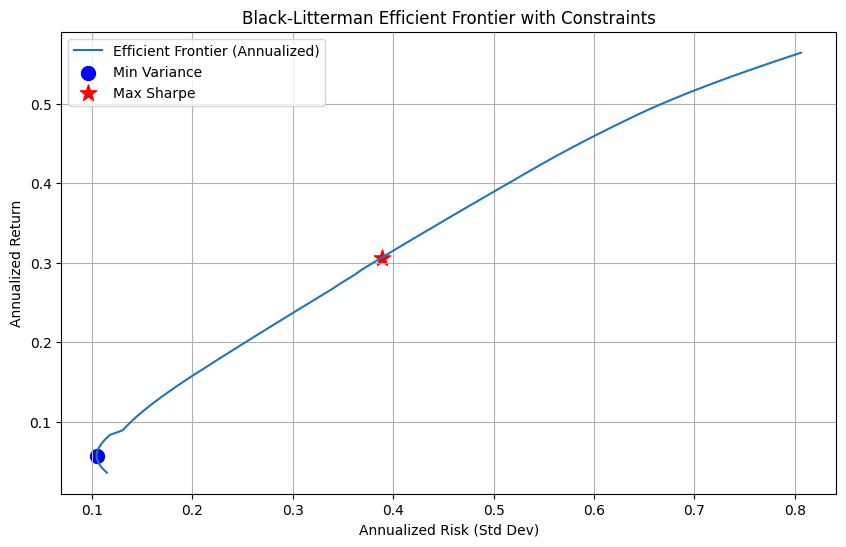

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(np.array(efficient_risks) * np.sqrt(12), target_returns * 12, label='Efficient Frontier (Annualized)')

# Ajout Min Variance
plt.scatter(vol_min_var * np.sqrt(12), ret_min_var * 12,
            color='blue', marker='o', s=100, label='Min Variance')

# Ajout Max Sharpe
plt.scatter(vol_max_sharpe * np.sqrt(12), ret_max_sharpe * 12,
            color='red', marker='*', s=150, label='Max Sharpe')

plt.xlabel('Annualized Risk (Std Dev)')
plt.ylabel('Annualized Return')
plt.title('Black-Litterman Efficient Frontier with Constraints')
plt.legend()
plt.grid(True)
plt.show()


### Comparaison with step 1

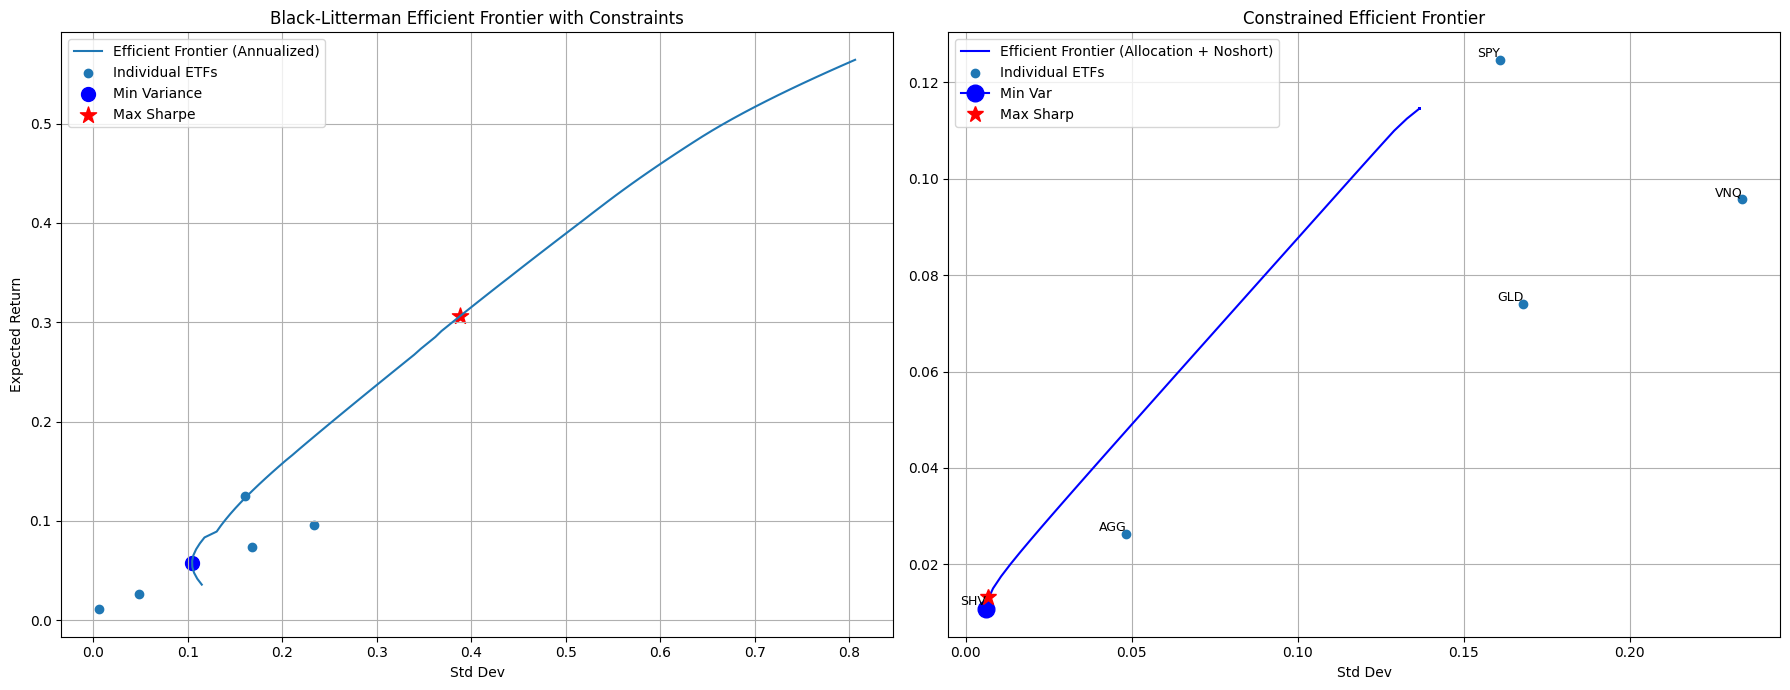

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(18, 7))

axs[0].plot(np.array(efficient_risks) * np.sqrt(12), target_returns * 12, label='Efficient Frontier (Annualized)')
axs[0].scatter(np.sqrt(np.diag(V)), ER, marker='o', label='Individual ETFs')

axs[0].scatter(vol_min_var * np.sqrt(12), ret_min_var * 12,
               color='blue', marker='o', s=100, label='Min Variance')
axs[0].scatter(vol_max_sharpe * np.sqrt(12), ret_max_sharpe * 12,
               color='red', marker='*', s=150, label='Max Sharpe')
axs[0].set_xlabel('Std Dev')
axs[0].set_ylabel('Expected Return')
axs[0].set_title('Black-Litterman Efficient Frontier with Constraints')
axs[0].legend()
axs[0].grid(True)


axs[1].plot(portfolio_std_devs3, portfolio_returns3, 'b', label='Efficient Frontier (Allocation + Noshort)')
axs[1].scatter(np.sqrt(np.diag(V)), ER, marker='o', label='Individual ETFs')

for i, ticker in enumerate(etfs_list):
    axs[1].text(np.sqrt(V[i, i]), ER[i], ticker, fontsize=9, ha='right', va='bottom')

axs[1].plot(s2, ER2, 'b', marker="o", markersize=12, label='Min Var')
axs[1].plot(s1, ER1, 'r*', markersize=12, label='Max Sharp')

axs[1].set_xlabel('Std Dev')
axs[1].set_title('Constrained Efficient Frontier')
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
plt.show()


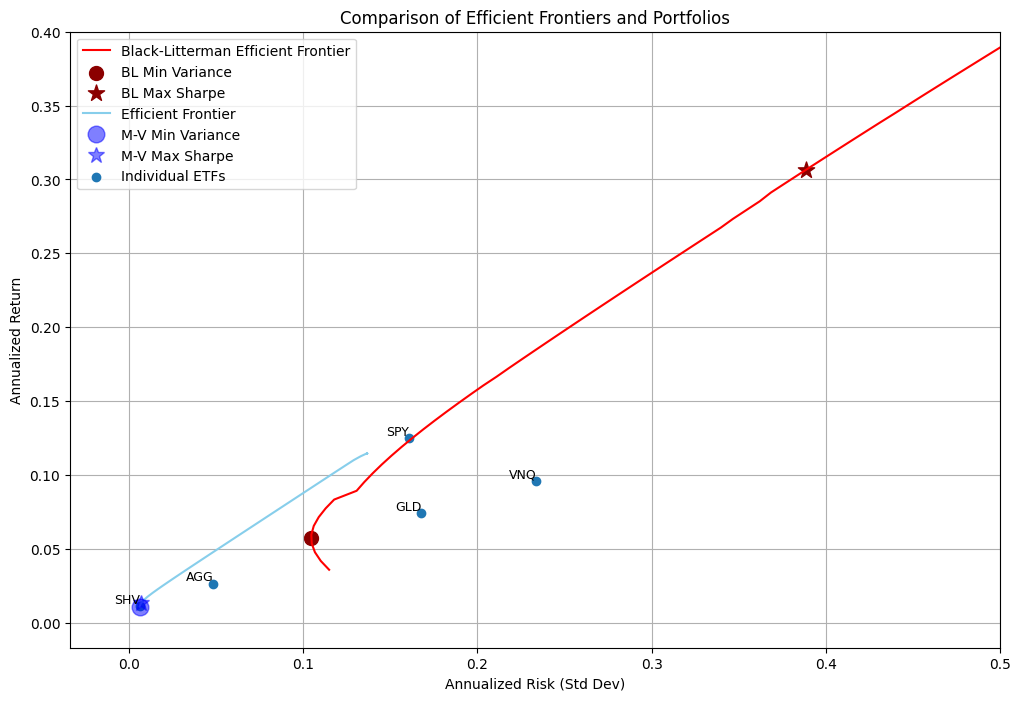

In [ ]:
plt.figure(figsize=(12, 8))

# BL model
plt.plot(np.array(efficient_risks) * np.sqrt(12), target_returns * 12,
         label='Black-Litterman Efficient Frontier', color='red')

plt.scatter(vol_min_var * np.sqrt(12), ret_min_var * 12,
            color='darkred', marker='o', s=100, label='BL Min Variance')

plt.scatter(vol_max_sharpe * np.sqrt(12), ret_max_sharpe * 12,
            color='darkred', marker='*', s=150, label='BL Max Sharpe')

# Mean-Variance model
plt.plot(portfolio_std_devs3, portfolio_returns3,
         label='Efficient Frontier', color='skyblue')

plt.plot(s2, ER2, 'bo', markersize=12, alpha=0.5, label='M-V Min Variance')

plt.plot(s1, ER1, 'b*', markersize=12, alpha=0.5, label='M-V Max Sharpe')

# ETFs
plt.scatter(np.sqrt(np.diag(V)), ER, marker='o', label='Individual ETFs')
for i, ticker in enumerate(etfs_list):
    plt.text(np.sqrt(V[i, i]), ER[i], ticker, fontsize=9, ha='right', va='bottom')

plt.xlabel('Annualized Risk (Std Dev)')
plt.ylabel('Annualized Return')
plt.title('Comparison of Efficient Frontiers and Portfolios')

plt.legend()
plt.grid(True)

#zoom in
plt.xlim(right=0.5)
plt.ylim(top=0.4)

plt.show()
